In [1]:
import pandas as pd
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print("Shape:", df.shape)
print()
df.info()
print()
print("Missing values:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Shape: (891, 12)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687


In [4]:
df_clean = df.copy()

# Remove duplicates
df_clean = df_clean.drop_duplicates()

# Fill missing Age with the median
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())

# Fill missing Embarked with the most common value
df_clean["Embarked"] = df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])

# Drop Cabin (too many missing values)
df_clean = df_clean.drop(columns=["Cabin"])

# Check the result
print("Missing values after cleaning:")
print(df_clean.isnull().sum())
print("New shape:", df_clean.shape)

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64
New shape: (891, 11)


In [5]:
# Summary statistics for numeric columns
print(df_clean.describe())

# Key counts
print("\nSurvival counts:")
print(df_clean["Survived"].value_counts())

print("\nPassengers by class:")
print(df_clean["Pclass"].value_counts())

print("\nSurvival rate by sex:")
print(df_clean.groupby("Sex")["Survived"].mean().round(2))

print("\nSurvival rate by class:")
print(df_clean.groupby("Pclass")["Survived"].mean().round(2))

print("\nAverage age:", round(df_clean["Age"].mean(), 1))
print("Average fare:", round(df_clean["Fare"].mean(), 2))

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  891.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.361582    0.523008   
std     257.353842    0.486592    0.836071   13.019697    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   22.000000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   35.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Passenger

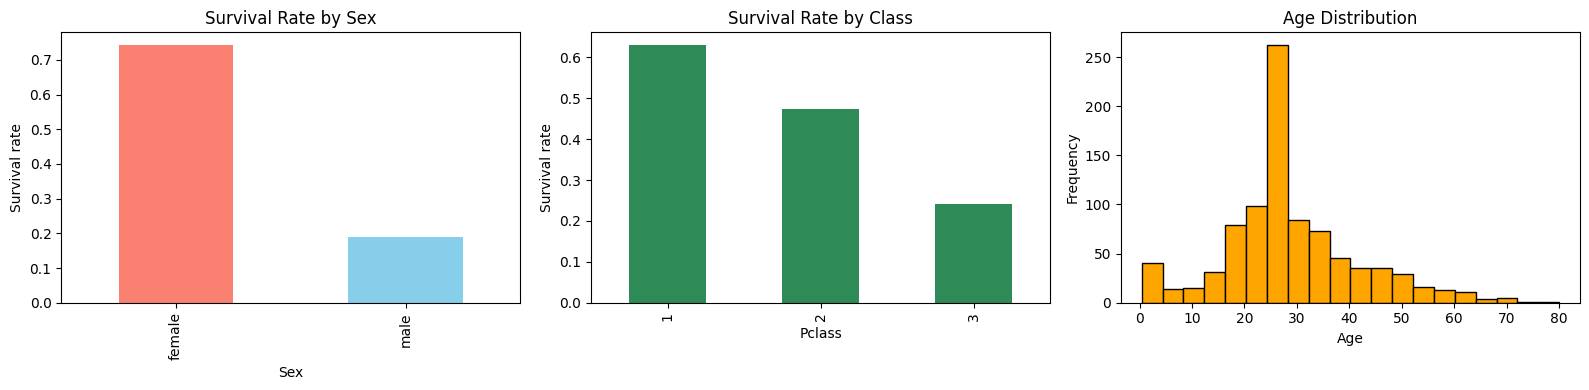

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Survival by sex
df_clean.groupby("Sex")["Survived"].mean().plot(kind="bar", ax=axes[0], color=["salmon", "skyblue"])
axes[0].set_title("Survival Rate by Sex")
axes[0].set_ylabel("Survival rate")

# Survival by class
df_clean.groupby("Pclass")["Survived"].mean().plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Survival Rate by Class")
axes[1].set_ylabel("Survival rate")

# Age distribution
df_clean["Age"].plot(kind="hist", bins=20, ax=axes[2], color="orange", edgecolor="black")
axes[2].set_title("Age Distribution")
axes[2].set_xlabel("Age")

plt.tight_layout()
plt.show()

In [7]:
df_clean.to_csv("titanic_cleaned.csv", index=False)
df.to_csv("titanic_raw.csv", index=False)

In [8]:
from google.colab import files
files.download("titanic_cleaned.csv")
files.download("titanic_raw.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>